# 04 Test: the chosen model on the test period, once

**Purpose:** Evaluate the final model, chosen on the backtest only, on the test period (2024-10 to 2026-09), together with the best simple baseline. This is the only notebook that uses the test period.
**Input:** `../data/processed/asylum_clean.csv` (from `01_preprocess.ipynb`) and `../output/tables/03_backtest_errors.csv` (from `03_evaluate.ipynb`).
**Output:** `../data/processed/test_forecasts.csv`, `../output/tables/04_test_errors.csv` and `../output/figures/04_test_forecasts_h2.png`.

**The choice was made before this notebook was run** (notebook 209, Step 7): `03_evaluate.ipynb`, section 8, chooses the **linear regression** of `02b` (it is as good as Ridge at $h = 2$ and simpler). That section was saved on GitHub before the test (commit `c6a3976`, 17 November 2026). We do not change the choice after seeing the results below; they are reported as they are (notebook 209, Step 8).

Section 8 was added after the test: it reports, for information only, the random walk and the second model family (the regressions with all indicators) on the same test months. It does not change the choice or anything above.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the whole series

For the first time, we use all 225 months, including the 24 months of the test period.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index

last_backtest = int(np.where(months == pd.Timestamp("2024-09-01"))[0][0])
last_month = len(months) - 1
H_MAX = 3

print(clean["period"].value_counts())
print("Last backtest month:", months[last_backtest], "| last month:", months[last_month])

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00


## 2. The two models, exactly as in the backtest

- **Linear regression** (`02b_estimate_regression.ipynb`): one model per horizon, predicting the change of log applications from the last two monthly changes, the same change one year earlier and the calendar month. The function `make_table` is copied without any change.
- **12-month average** (`02_estimate.ipynb`): the average of the last 12 known months, for every horizon.

In [3]:
def make_table(h):
    # Copied from 02b: one row per origin t, features known at t, target = change of log from t to t + h
    rows = []
    for t in range(12, len(log_y) - h):
        rows.append({
            "t": t,
            "change_last_month": log_y[t] - log_y[t - 1],
            "change_month_before": log_y[t - 1] - log_y[t - 2],
            "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
            "calendar_month": months[t + h].month,
            "target": log_y[t + h] - log_y[t],
        })
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    X = pd.concat([table[["change_last_month", "change_month_before", "same_change_last_year"]], dummies], axis=1)
    return X, table["target"]


def average_12(train_y, h_max):
    # Copied from 02: average of the last 12 known months, the same for every horizon
    average = train_y[-12:].mean()
    return np.log(np.full(h_max, average))


tables = {h: make_table(h) for h in range(1, H_MAX + 1)}

## 3. Forecasts for the test period

We continue the backtest into the test period with the same rule: at each origin, the models are fitted on **all months known at that origin and nothing after it**, and we forecast $h = 1, 2, 3$. The origins go from September 2024 (the last backtest month) to August 2026. So the forecasts for, say, March 2026 are made with the months up to December 2025 ($h = 3$), January 2026 ($h = 2$) or February 2026 ($h = 1$), as a planner would have had them.

This is the time-series version of "refit on all training data, then test" (notebook 209, Step 8): there is no single refit, because in practice the model is refitted every month when a new number arrives. We expect 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$ per model.

In [4]:
rows = []

for t in range(last_backtest, last_month):          # origins 2024-09 to 2026-08
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_month:
            continue

        # Linear regression: training rows whose target is known at the origin
        X, target = tables[h]
        train_rows = list(range(X.index.min(), t - h + 1))
        assert max(train_rows) + h <= t                     # no training target after the origin
        model = make_pipeline(StandardScaler(), LinearRegression()).fit(X.loc[train_rows], target.loc[train_rows])
        forecast_lr = log_y[t] + model.predict(X.loc[[t]])[0]

        # 12-month average: the last 12 months up to the origin
        forecast_avg = average_12(y[: t + 1], H_MAX)[h - 1]

        for name, forecast_log in [("Linear regression", forecast_lr), ("12-month average", forecast_avg)]:
            rows.append({
                "model": name, "origin": months[t], "month": months[target_pos], "h": h,
                "forecast_log": forecast_log, "actual_log": log_y[target_pos],
                "forecast": np.exp(forecast_log), "actual": y[target_pos],
            })

test_forecasts = pd.DataFrame(rows)
print(test_forecasts.groupby(["model", "h"]).size())
print()
print("All forecast months in the test period:", (test_forecasts["month"] >= pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (test_forecasts["month"] > test_forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(test_forecasts["forecast_log"])).sum())

model              h
12-month average   1    24
                   2    23
                   3    22
Linear regression  1    24
                   2    23
                   3    22
dtype: int64

All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0


**What we see.** Each model has 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$, as expected. All forecast months lie in the test period and after their origin, and no forecast is missing. Together with the `assert` in the loop, this shows that each forecast used only the months known at its origin.

## 4. Test errors

The same two error measures as in `03_evaluate.ipynb`: the MAE in persons (main) and the RMSE in logs.

In [5]:
test_forecasts["abs_error"] = (test_forecasts["actual"] - test_forecasts["forecast"]).abs()
test_forecasts["sq_error_log"] = (test_forecasts["actual_log"] - test_forecasts["forecast_log"]) ** 2

grouped = test_forecasts.groupby(["model", "h"])
test_errors = pd.DataFrame({
    "MAE (persons)": grouped["abs_error"].mean(),
    "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
    "forecasts": grouped["abs_error"].size(),
}).reset_index()

test_errors.to_csv("../output/tables/04_test_errors.csv", index=False)
test_errors.round(3)

,model,h,MAE (persons),RMSE (log),forecasts
0,12-month average,1,297.309,0.177,24
1,12-month average,2,331.286,0.191,23
2,12-month average,3,359.299,0.204,22
3,Linear regression,1,149.287,0.098,24
4,Linear regression,2,187.966,0.112,23
5,Linear regression,3,217.125,0.144,22


### The main comparison at $h = 2$

In [6]:
h2 = test_errors[test_errors["h"] == 2].set_index("model")
mae_lr, mae_avg = h2.loc["Linear regression", "MAE (persons)"], h2.loc["12-month average", "MAE (persons)"]
rmse_lr, rmse_avg = h2.loc["Linear regression", "RMSE (log)"], h2.loc["12-month average", "RMSE (log)"]

print(f"Test MAE at h=2: linear regression {mae_lr:.1f} persons, 12-month average {mae_avg:.1f} persons")
print(f"Improvement: {100 * (1 - mae_lr / mae_avg):.0f}% lower MAE, {100 * (1 - rmse_lr / rmse_avg):.0f}% lower RMSE (log)")
print("Success rule of our plan (at least 10% lower MAE than the best simple baseline):", mae_lr <= 0.9 * mae_avg)
print(f"For comparison, average actual number of applications in these months: {test_forecasts[test_forecasts['h'] == 2]['actual'].mean():.0f}")

Test MAE at h=2: linear regression 188.0 persons, 12-month average 331.3 persons
Improvement: 43% lower MAE, 41% lower RMSE (log)
Success rule of our plan (at least 10% lower MAE than the best simple baseline): True
For comparison, average actual number of applications in these months: 1982


**What we see.**
- At $h = 2$, the linear regression misses by **188 applications per month** on average, against 331 for the 12-month average: **43% lower MAE** and 41% lower RMSE (log) (0.112 against 0.191). Our success rule (at least 10% better than the best simple baseline) is met.
- In these months there were on average 1,982 applications per month, so the model misses by about a tenth of a typical month.
- The ranking is the same at the other horizons: 149 against 297 at $h = 1$, 217 against 359 at $h = 3$ (table above).

**What this means for us.** The model we chose on the backtest also clearly beats the simple rule on months it has never seen. The gain is in the same direction as in the backtest (32% there), so the result of the backtest holds up on new data.

## 5. Test against backtest

How do the test errors compare with the backtest errors of the same models (from `03_evaluate.ipynb`)? The backtest error of the chosen model is a little too optimistic, because it won the comparison (notebook 108b). The two periods also differ in how hard they are: we put the average number of applications next to the errors.

In [7]:
backtest = pd.read_csv("../output/tables/03_backtest_errors.csv").set_index("model")

comparison = pd.DataFrame(index=["Linear regression", "12-month average"])
for h in [1, 2, 3]:
    comparison[f"backtest MAE h={h}"] = backtest.loc[comparison.index, f"MAE h={h}"]
    comparison[f"test MAE h={h}"] = [test_errors[(test_errors["model"] == m) & (test_errors["h"] == h)]["MAE (persons)"].iloc[0]
                                     for m in comparison.index]
print(comparison.round(0))
print()
level = clean.groupby("period")["applicants_total"].agg(["mean", "std"]).round(0)
print("Applications per month in each period:")
print(level)

                   backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression             256.0         149.0             358.0   
12-month average              487.0         297.0             528.0   

                   test MAE h=2  backtest MAE h=3  test MAE h=3  
Linear regression         188.0             452.0         217.0  
12-month average          331.0             558.0         359.0  

Applications per month in each period:
            mean    std
period                 
backtest  1852.0  888.0
test      2008.0  338.0
training  1678.0  561.0


**What we see.**
- Both models have **much smaller errors in the test period** than in the backtest: the linear regression 188 instead of 358 at $h = 2$, the 12-month average 331 instead of 528.
- The test period is much calmer: the standard deviation of the monthly applications is 338, against 888 in the backtest, for a similar average (2,008 against 1,852).

**What this means for us.** The smaller test errors come mostly from an **easier period**, not from a model that got better: the simple rule improves just as much. This is why we compare the two models on the same months, and not the test error with the backtest error. With only 23 forecasts at $h = 2$, the test MAE is also uncertain; we report it as one honest check, not as the error to expect in every future year. In a new crisis like 2015-16, the errors would be much larger (`03_evaluate.ipynb`, section 5).

## 6. The forecasts two months ahead, month by month

The table shows what a planner would have seen: for each month of the test period, the forecast made two months earlier and the actual number.

In [8]:
h2_forecasts = test_forecasts[test_forecasts["h"] == 2]
monthly = h2_forecasts.pivot(index="month", columns="model", values="forecast").round(0)
monthly.insert(0, "Actual", h2_forecasts.groupby("month")["actual"].first())
monthly["error of the linear regression"] = monthly["Linear regression"] - monthly["Actual"]
monthly

model,Actual,12-month average,Linear regression,error of the linear regression
month,,,,
2024-11-01,2320.0,2485.0,2480.0,160.0
2024-12-01,1850.0,2409.0,2179.0,329.0
2025-01-01,1910.0,2341.0,2118.0,208.0
2025-02-01,1765.0,2308.0,1702.0,-63.0
2025-03-01,1825.0,2237.0,1642.0,-183.0
2025-04-01,1890.0,2180.0,1573.0,-317.0
2025-05-01,2020.0,2134.0,1723.0,-297.0
2025-06-01,2210.0,2102.0,2270.0,60.0
2025-07-01,2480.0,2074.0,2441.0,-39.0


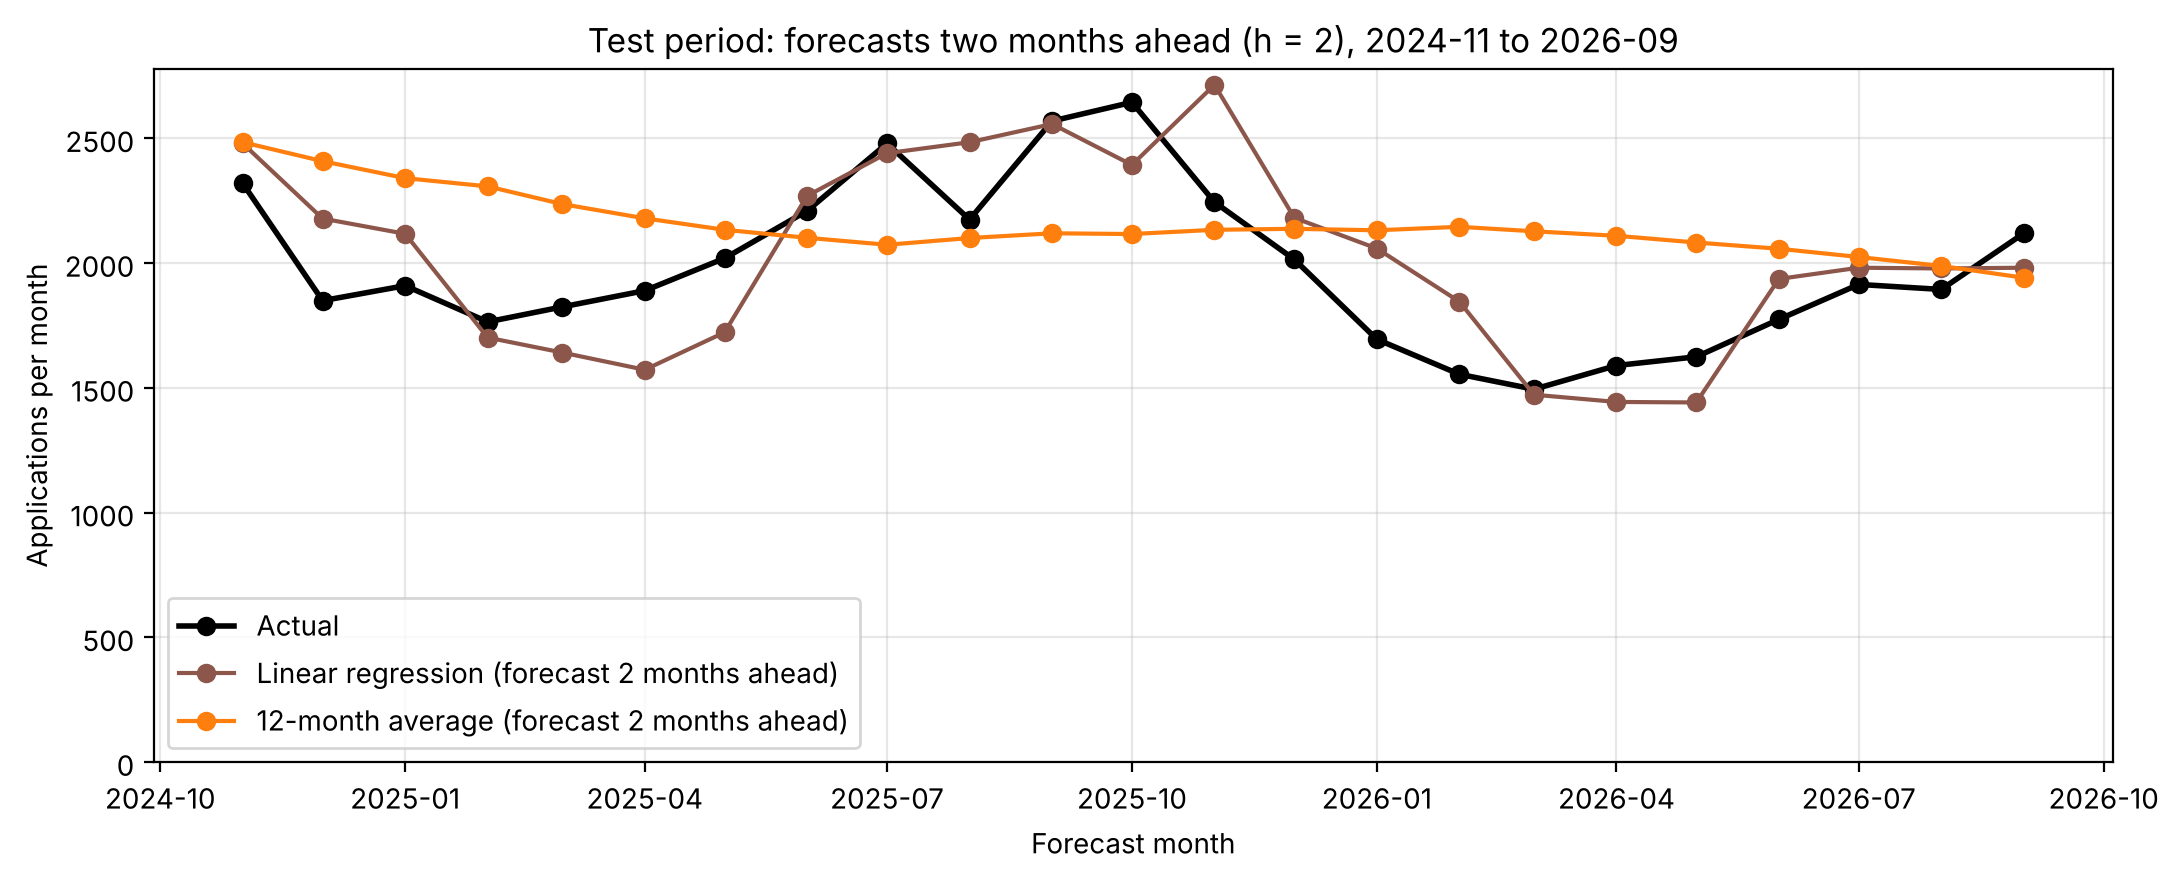

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Actual"], color="black", linewidth=2, marker="o", label="Actual")
ax.plot(monthly.index, monthly["Linear regression"], color=plt.cm.tab10(5), marker="o", label="Linear regression (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["12-month average"], color=plt.cm.tab10(1), marker="o", label="12-month average (forecast 2 months ahead)")
ax.set_title("Test period: forecasts two months ahead (h = 2), 2024-11 to 2026-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/04_test_forecasts_h2.png")
plt.show()

**What we see.**
- The 12-month average is almost a flat line around 2,000 to 2,500: it cannot follow the rise in summer and autumn 2025 or the fall in early 2026.
- The linear regression follows the seasonal pattern (the rise from June to October 2025 and again from June 2026). In 14 of the 23 months, it misses by 200 or less (table above).
- Its largest errors come right **after turning points**: it was too low in March to May 2025 (−183 to −317) and too high in November 2025 to February 2026 (+470 in November, +364 in January), when the numbers had already turned down.

**What this means for us.** The model reacts to the newest changes, but only once they are visible in the data. A planner can use it as a monthly guide, but should expect misses of a few hundred applications at turning points.

## 7. Save the test forecasts

In [10]:
test_forecasts.drop(columns=["abs_error", "sq_error_log"]).to_csv("../data/processed/test_forecasts.csv", index=False)
print("Saved", test_forecasts.shape[0], "test forecasts")

Saved 138 test forecasts


## 8. Added after the test: the random walk and the second model family

The random walk (the last known month, `02_estimate.ipynb`) and the models with indicators (`02c_estimate_indicator.ipynb`, Part B) were added after this notebook had been run once (`03_evaluate.ipynb`, Part B). We report how they do on the same test months, for information only. This does not change the choice or the test result above.

First the random walk: it has nothing to fit and nothing to choose.

In [11]:
test_rw = test_forecasts[test_forecasts["model"] == "Linear regression"].copy()
test_rw["model"] = "Random walk"
test_rw["forecast"] = clean.loc[test_rw["origin"], "applicants_total"].to_numpy()
test_rw["abs_error"] = (test_rw["actual"] - test_rw["forecast"]).abs()
test_all = pd.concat([test_forecasts, test_rw], ignore_index=True)
test_all.pivot_table(index="model", columns="h", values="abs_error", aggfunc="mean").round(0)

h,1,2,3
model,,,
12-month average,297.0,331.0,359.0
Linear regression,149.0,188.0,217.0
Random walk,187.0,269.0,358.0


**What we see.** In the test period, the random walk misses by 269 applications at $h = 2$, between the linear regression (188) and the 12-month average (331). Here the linear regression is 30% better than the random walk, against only 5.4% in the backtest (`03_evaluate.ipynb`, section 11): the test period has a clear seasonal pattern, which the random walk ignores (section 6).

### The two model families on the test months (information only)

`03_evaluate.ipynb` (section 16) names **model 2**, the best model with all indicators in the backtest. Here we run both families on the test origins with the same rules as in the backtest (features known at the cutoff, `alpha` chosen on the two validation blocks inside each training window, refit at every origin): the three regressions on the own past and with all indicators, and model 2's regression with each block alone and with all blocks but one, to see **which data lower the error on new months**. The functions are copied from `02b` and `02c` (Part B); we first check that the copy gives the same backtest forecasts.

**Two limits.** (1) UCDP's conflict deaths end in December 2025, so every model with the conflict index can only forecast from origins up to January 2026; to compare like with like, all models are scored on the **same forecast months**, those where every model has a forecast. (2) **This is information only.** We already know the test result of model 1, so choosing a model because of these numbers would use the test twice. The choice stays the linear regression.

In [12]:
import warnings
from sklearn.linear_model import Ridge, Lasso

def load_ind(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    return data.set_index("month")

routes_ind = load_ind("../data/processed/routes_clean.csv").reindex(months)
extra_ind = load_ind("../data/processed/extra_indicators_clean.csv").reindex(months)
shares = load_ind("../data/processed/nationality_shares_clean.csv").reindex(months)
intensity = load_ind("../data/processed/conflict_intensity_clean.csv")
log_routes = routes_ind["log_routes"].to_numpy(dtype=float)
log_neighbours = extra_ind["log_neighbours"].to_numpy(dtype=float)
log_med = extra_ind["log_med_routes"].to_numpy(dtype=float)

def conflict_change(t, k):
    # Copied from 02c (Part B)
    w = shares.iloc[t]
    if w.isna().all():
        return np.nan
    top = w.nlargest(10)
    m1 = months[t] - pd.DateOffset(months=1)
    m0 = months[t] - pd.DateOffset(months=1 + k)
    if m1 not in intensity.index or m0 not in intensity.index:
        return np.nan
    change = intensity.loc[m1, top.index] - intensity.loc[m0, top.index]
    weighted = top * change
    return float(weighted.sum()) if weighted.notna().all() else np.nan    # NaN if a month is not in UCDP yet

conflict_3 = np.array([conflict_change(t, 3) for t in range(len(months))])
conflict_6 = np.array([conflict_change(t, 6) for t in range(len(months))])

features = {   # copied from 02c (Part B)
    "routes": {"routes_change_last_month": lambda t: log_routes[t - 1] - log_routes[t - 2],
               "routes_change_3_months": lambda t: log_routes[t - 1] - log_routes[t - 4]},
    "neighbours": {"neighbours_change_last_month": lambda t: log_neighbours[t - 1] - log_neighbours[t - 2],
                   "neighbours_change_3_months": lambda t: log_neighbours[t - 1] - log_neighbours[t - 4]},
    "Med routes": {"med_change_last_month": lambda t: log_med[t] - log_med[t - 1],
                   "med_change_3_months": lambda t: log_med[t] - log_med[t - 3]},
    "conflict": {"conflict_3_months": lambda t: conflict_3[t], "conflict_6_months": lambda t: conflict_6[t]},
}
indicators = list(features)

def make_table_ind(h, parts):
    # Copied from 02c (Part B); with no block it is the table of 02b
    extra_features = {k: f for b in parts for k, f in features[b].items()}
    rows = []
    for t in range(12, len(log_y) - h):
        values = {name: f(t) for name, f in extra_features.items()}
        if any(np.isnan(v) for v in values.values()):
            continue
        rows.append({"t": t,
                     "change_last_month": log_y[t] - log_y[t - 1],
                     "change_month_before": log_y[t - 1] - log_y[t - 2],
                     "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
                     **values,
                     "calendar_month": months[t + h].month,
                     "target": log_y[t + h] - log_y[t]})
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    names = ["change_last_month", "change_month_before", "same_change_last_year"] + list(extra_features)
    return pd.concat([table[names], dummies], axis=1), table["target"]

def make_model(name, alpha=None):
    # Copied from 02b
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

alpha_grids = {"Linear regression": [None], "Ridge": [0.1, 1, 10, 100, 1000, 10000],
               "Lasso": [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

def choose_alpha(name, X, target, T, h, n_blocks=2, block=12):
    # Copied from 02b
    grid = alpha_grids[name]
    if len(grid) == 1:
        return grid[0]
    first_row, last_row = X.index.min(), T - h
    scores = []
    for alpha in grid:
        mse_blocks = []
        for b in range(n_blocks):
            start = last_row - n_blocks * block + 1 + b * block
            valid_rows = list(range(start, start + block))
            train_rows = list(range(first_row, start - h + 1))
            model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
            errors = target.loc[valid_rows].to_numpy() - model.predict(X.loc[valid_rows])
            mse_blocks.append(np.mean(errors ** 2))
        scores.append(np.mean(mse_blocks))
    return grid[int(np.argmin(scores))]

tables_ind = {}
def forecast_ind(name, parts, t, h):
    # one forecast of log applications at origin t, horizon h; NaN if a feature is not known at t
    key = (tuple(parts), h)
    if key not in tables_ind:
        tables_ind[key] = make_table_ind(h, parts)
    X, target = tables_ind[key]
    if t not in X.index:
        return np.nan
    train_rows = list(range(X.index.min(), t - h + 1))
    assert max(train_rows) + h <= t                       # no training target after the origin
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        alpha = choose_alpha(name, X, target, t, h)
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
    return log_y[t] + model.predict(X.loc[[t]])[0]

model_2 = pd.read_csv("../output/tables/03_two_models.csv").set_index("family").loc["all indicators", "model"]
own_2 = model_2.split(" + ")[0]

# Check the copy at the last backtest origin (2024-08, h = 1) against the stored forecasts of 02b and 02c
stored = pd.concat([pd.read_csv("../data/processed/backtest_forecasts_regression.csv"),
                    pd.read_csv("../data/processed/backtest_forecasts_extra.csv")])
t_check = last_backtest - 1
for name in alpha_grids:
    for label, parts in [(name, []), (f"{name} + all indicators", indicators)]:
        s = stored[(stored["model"] == label) & (stored["origin"] == str(months[t_check].date())) & (stored["h"] == 1)]
        assert np.isclose(forecast_ind(name, parts, t_check, 1), s["forecast_log"].iloc[0]), label
print("The copied functions reproduce the backtest forecasts of 02b and 02c. Model 2:", model_2)

The copied functions reproduce the backtest forecasts of 02b and 02c. Model 2: Ridge + all indicators


In [13]:
# The runs: both families with all three regressions, and model 2's regression with every combination
runs = {}
for name in alpha_grids:
    runs[name] = (name, [])
    runs[f"{name} + all indicators"] = (name, indicators)
for b in indicators:
    runs[f"{own_2} + {b}"] = (own_2, [b])
    runs[f"{own_2} + all but {b}"] = (own_2, [x for x in indicators if x != b])

rows = []
for t in range(last_backtest, last_month):               # the same test origins as above
    for h in range(1, H_MAX + 1):
        if t + h > last_month:
            continue
        for label, (name, parts) in runs.items():
            rows.append({"model": label, "origin": months[t], "month": months[t + h], "h": h,
                         "forecast_log": forecast_ind(name, parts, t, h), "actual_log": log_y[t + h],
                         "actual": y[t + h]})
test_ind = pd.DataFrame(rows)

# Score every model on the same forecast months: those where every model has a forecast
complete = test_ind.groupby(["origin", "h"])["forecast_log"].apply(lambda f: f.notna().all())
common = complete[complete].index
test_ind = test_ind.set_index(["origin", "h"]).loc[common].reset_index()
test_ind["abs_error"] = (test_ind["actual"] - np.exp(test_ind["forecast_log"])).abs()
test_ind["sq_error_log"] = (test_ind["actual_log"] - test_ind["forecast_log"]) ** 2
print("Forecast months used:", test_ind.groupby("h")["month"].agg(["min", "max", "nunique"]).to_dict("index"))

grouped = test_ind.groupby(["model", "h"])
test_info = pd.DataFrame({"MAE (persons)": grouped["abs_error"].mean(), "MSE (log)": grouped["sq_error_log"].mean()}).unstack("h")
order = (list(alpha_grids) + [f"{n} + all indicators" for n in alpha_grids]
         + [f"{own_2} + {b}" for b in indicators] + [f"{own_2} + all but {b}" for b in indicators])
test_info = test_info.loc[order]
test_info.to_csv("../output/tables/04_test_errors_added_after.csv")
test_info.round({("MAE (persons)", 1): 0, ("MAE (persons)", 2): 0, ("MAE (persons)", 3): 0,
                 ("MSE (log)", 1): 4, ("MSE (log)", 2): 4, ("MSE (log)", 3): 4})

Forecast months used: {1: {'min': Timestamp('2024-10-01 00:00:00'), 'max': Timestamp('2026-02-01 00:00:00'), 'nunique': 17}, 2: {'min': Timestamp('2024-11-01 00:00:00'), 'max': Timestamp('2026-03-01 00:00:00'), 'nunique': 17}, 3: {'min': Timestamp('2024-12-01 00:00:00'), 'max': Timestamp('2026-04-01 00:00:00'), 'nunique': 17}}


MAE (persons)               MSE (log)  \
h                                              1      2      3         1   
model                                                                      
Linear regression                          169.0  208.0  250.0    0.0107   
Ridge                                      153.0  230.0  259.0    0.0085   
Lasso                                      179.0  222.0  250.0    0.0104   
Linear regression + all indicators         192.0  236.0  280.0    0.0138   
Ridge + all indicators                     163.0  235.0  284.0    0.0100   
Lasso + all indicators                     178.0  238.0  287.0    0.0116   
Ridge + routes                             149.0  230.0  255.0    0.0086   
Ridge + neighbours                         145.0  231.0  269.0    0.0088   
Ridge + Med routes                         162.0  255.0  264.0    0.0098   
Ridge + conflict                           161.0  231.0  271.0    0.0092   
Ridge + all but routes                     163.0  249.0  298.0    0.0099   
Ridge + all but neighbours                 167.0  232.0  274.0    0.0101   
Ridge + all but Med routes                 157.0  220.0  266.0    0.0094   
Ridge + all but conflict                   152.0  251.0  268.0    0.0097   

                                                    
h                                        2       3  
model                                               
Linear regression                   0.0148  0.0257  
Ridge                               0.0165  0.0293  
Lasso                               0.0178  0.0257  
Linear regression + all indicators  0.0204  0.0285  
Ridge + all indicators              0.0204  0.0303  
Lasso + all indicators              0.0206  0.0302  
Ridge + routes                      0.0164  0.0286  
Ridge + neighbours                  0.0170  0.0293  
Ridge + Med routes                  0.0215  0.0279  
Ridge + conflict                    0.0179  0.0309  
Ridge + all but routes              0.0202  0.0308  
Ridge + all but neighbours          0.0207  0.0291  
Ridge + all but Med routes          0.0163  0.0302  
Ridge + all but conflict            0.0212  0.0291

Which data lower the error on the test months? As in `03_evaluate.ipynb` (section 13): the rise in the MSE (log) when one block is removed from model 2 (positive = the block was helping).

In [14]:
mse_test = test_info["MSE (log)"]
pd.DataFrame({f"h={h}": [100 * (mse_test.loc[f"{own_2} + all but {b}", h] / mse_test.loc[model_2, h] - 1) for b in indicators]
              for h in [1, 2, 3]}, index=pd.Index(indicators, name="block removed")).round(1)

,h=1,h=2,h=3
block removed,,,
routes,-1.4,-0.8,1.5
neighbours,0.5,1.5,-3.9
Med routes,-6.3,-19.9,-0.4
conflict,-3.7,4.3,-4.1


**What we see.**
- Because UCDP ends in December 2025, the comparison uses the **17 forecast months per horizon** where every model has a forecast (up to 2026-03 at $h = 2$), not all 23. So model 1's MAE here (208) differs from section 4 (188).
- **Model 1 stays the best at $h = 2$:** the linear regression misses by 208 applications, model 2 (Ridge + all indicators) by 235, 13% more, with a 38% higher MSE (log) (0.0204 against 0.0148). Each regression with all indicators is worse than the same regression without them, at all three horizons.
- **Which data help on new months? Not the same as in the backtest.** Removing the Mediterranean routes from model 2 *lowers* the MSE at $h = 2$ by 20% (MAE 220 instead of 235): the block that helped most in the backtest hurts most here. The other blocks change the MSE by −1% to +4%.

**What this means for us.** The small backtest gain of the indicators does not hold on months the models have not seen, and the ranking of the data sources is not stable. This supports our choice and the caution of `03_evaluate.ipynb` (section 19): with about 200 training months, the extra data add more noise than signal two months ahead. We did not change anything because of these numbers.

## Summary

- **Choice (made before this notebook, `03_evaluate.ipynb` section 8):** the linear regression on the series' own past.
- **Test result at $h = 2$:** MAE 188 applications per month against 331 for the 12-month average, **43% lower**; RMSE (log) 41% lower. The success rule of our plan is met, and the ranking holds at $h = 1$ and $h = 3$.
- **Careful reading:** the test period (2024-10 to 2026-09) was calm, so both models have smaller errors than in the backtest; only 23 forecasts at $h = 2$; the largest misses come after turning points.
- **Added after the test (section 8):** the random walk misses by 269 at $h = 2$; the linear regression is 30% better.
- **Information only (section 8):** on the 17 test months where every model can forecast, model 2 (Ridge + all indicators) misses by 235 at $h = 2$ against 208 for model 1 (13% more); the Mediterranean routes, the most useful block in the backtest, make the test forecasts worse. The small backtest gain of the indicators does not hold.
- **The test period was used once.** The choice was not changed after seeing these results.